# Контрольная работа: Кластеризация

**Выполнил:** Бушуев Никита

**Цель работы:** изучить алгоритм KMeans, выполнить стандартизацию данных, сравнить результаты для двух, трёх и четырёх кластеров с помощью визуализации, коэффициента силуэта и метода локтя.

## 1. Функция создания данных

Подключаем библиотеки и определяем функцию `make_data`. Параметр `n` задаёт число объектов в каждой из трёх групп, `seed` обеспечивает воспроизводимость результата.

In [103]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
pd.set_option('display.precision', 6)
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.family'] = 'DejaVu Sans'
results_dir = Path('results_kr')
results_dir.mkdir(exist_ok=True)


def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    df = df.sample(frac=1.0)
    return df

Функция формирует три группы точек с двумя числовыми признаками `x` и `y`. После умножения координат теоретические центры групп равны `(60, 1.5)`, `(120, 4.5)` и `(180, 1.5)`. Масштабы признаков различаются, поэтому перед KMeans потребуется стандартизация.

## 2. Создание и обзор данных

Выбираем `n = 50` и `seed = 42`. Получаем 150 объектов, перемешанных в случайном порядке. Проверяем размер, первые строки, типы данных, пропуски и дубликаты.

In [104]:
n = 50
seed = 42
df = make_data(n=n, seed=seed)

print(f'Размер набора: {df.shape[0]} строк, {df.shape[1]} столбца')
display(df.head(10))
df.info()
print('\nКоличество пропусков:')
print(df.isna().sum())
print('\nКоличество дубликатов:', df.duplicated().sum())

Размер набора: 150 строк, 2 столбца


,x,y
33,38.845781,1.240865
23,31.505036,2.282322
50,91.692585,4.625246
63,169.264842,4.089659
88,136.270344,4.076603
78,121.993027,4.367672
87,113.558770,4.463586
1,57.234714,1.307459
72,148.055886,4.461449
46,50.787225,1.648060


<class 'pandas.core.frame.DataFrame'>
Index: 150 entries, 33 to 137
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       150 non-null    float64
 1   y       150 non-null    float64
dtypes: float64(2)
memory usage: 3.5 KB

Количество пропусков:
x    0
y    0
dtype: int64

Количество дубликатов: 0


Получено 150 строк и 2 столбца. Оба признака имеют тип `float64`. Пропуски и явные дубликаты отсутствуют, дополнительная очистка не требуется. Индекс после перемешивания не является признаком и в модель не передаётся.

,count,mean,std,min,25%,50%,75%,max
x,150.0,119.241386,55.999458,20.806598,67.032764,120.337163,166.959349,257.054630
y,150.0,2.513417,1.515214,-0.120634,1.346669,1.859191,4.115373,5.860085


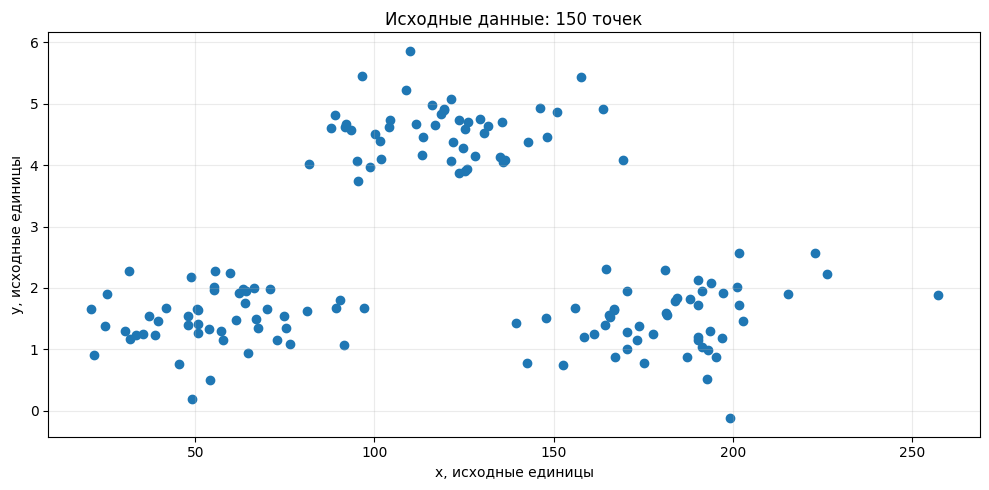

In [105]:
display(df.describe().T)

plt.scatter(df['x'], df['y'])
plt.xlabel('x, исходные единицы')
plt.ylabel('y, исходные единицы')
plt.title('Исходные данные: 150 точек')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

На диаграмме различимы три облака. Числовой разброс `x` значительно больше разброса `y`. Без масштабирования различия по `x` непропорционально влияли бы на евклидовы расстояния между точками.

## 3. Стандартизация данных

Применяем `StandardScaler` только к признакам `x` и `y`. Обучающее среднее вычитается из каждого значения, затем результат делится на обучающее стандартное отклонение. В проверке используем `ddof = 0`, как в StandardScaler.

,Признак,Среднее до,Std до,Среднее после,Std после
0,x,119.241386,55.812480,2.945792e-16,1.0
1,y,2.513417,1.510155,-4.322468e-16,1.0


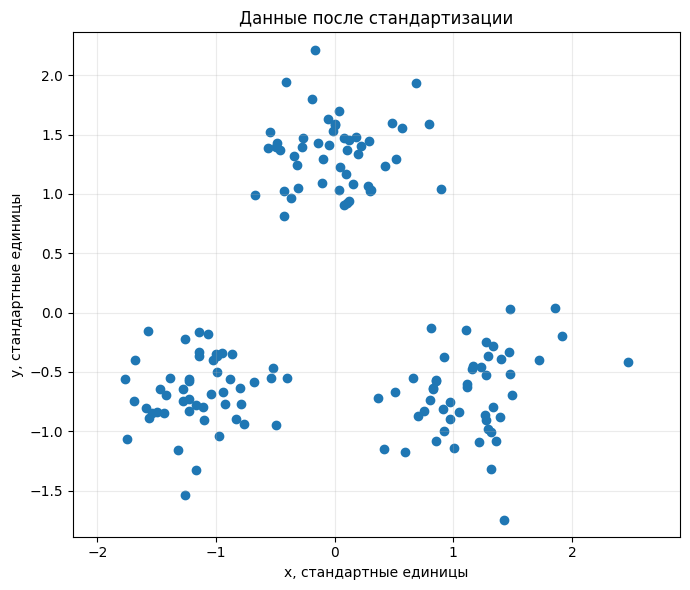

In [106]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[['x', 'y']])

scaler_parameters = pd.DataFrame({
    'Признак': ['x', 'y'],
    'Среднее до': scaler.mean_,
    'Std до': scaler.scale_,
    'Среднее после': X_scaled.mean(axis=0),
    'Std после': X_scaled.std(axis=0, ddof=0)
})
display(scaler_parameters)

plt.figure(figsize=(7, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1])
plt.xlabel('x, стандартные единицы')
plt.ylabel('y, стандартные единицы')
plt.title('Данные после стандартизации')
plt.axis('equal')
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

После преобразования средние значения обоих признаков близки к 0, стандартные отклонения равны 1. Устранено различие масштабов. Стандартизация не делает распределение данных автоматически нормальным. Далее модели обучаются на `X_scaled`.

## 4. KMeans для трёх кластеров

Обучаем модель методом `fit_predict`, задав `n_clusters = 3`. Фиксируем `random_state = 42` и `n_init = 30` для воспроизводимости. Выводим метки кластеров, численности групп и центры. Координаты центров возвращаем в исходные единицы через `inverse_transform`.

In [107]:
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=30, algorithm='lloyd')
clusters_3 = kmeans_3.fit_predict(X_scaled)
centers_3 = scaler.inverse_transform(kmeans_3.cluster_centers_)

print('Метки первых 20 объектов:')
print(clusters_3[:20])
print('\nКоличество объектов в кластерах:')
display(pd.Series(clusters_3).value_counts().sort_index().rename_axis('Кластер').to_frame('Объектов'))
print('Центры в исходных единицах:')
display(pd.DataFrame(centers_3, columns=['x', 'y']).rename_axis('Кластер'))
print(f'Инерция: {kmeans_3.inertia_:.6f}')

Метки первых 20 объектов:
[2 2 0 0 0 0 0 2 0 2 0 1 1 1 1 2 0 1 1 0]

Количество объектов в кластерах:


,Объектов
Кластер,
0,50
1,50
2,50


Центры в исходных единицах:


,x,y
Кластер,,
0,119.214249,4.541948
1,183.019387,1.489412
2,55.490522,1.508890


Инерция: 34.144525


Сформированы 3 кластера по 50 объектов. Центры близки к теоретическим центрам генерации. Инерция равна 34.144525. Номера кластеров условны: их перестановка не изменяет качество разбиения.

## 5. Визуализация кластеров и центров

Строим scatter: каждому кластеру соответствует свой цвет, центры отмечаем чёрными крестами. Графики отображаются в исходных единицах, хотя модель обучена на стандартизированных признаках. Функцию визуализации далее используем для всех моделей.

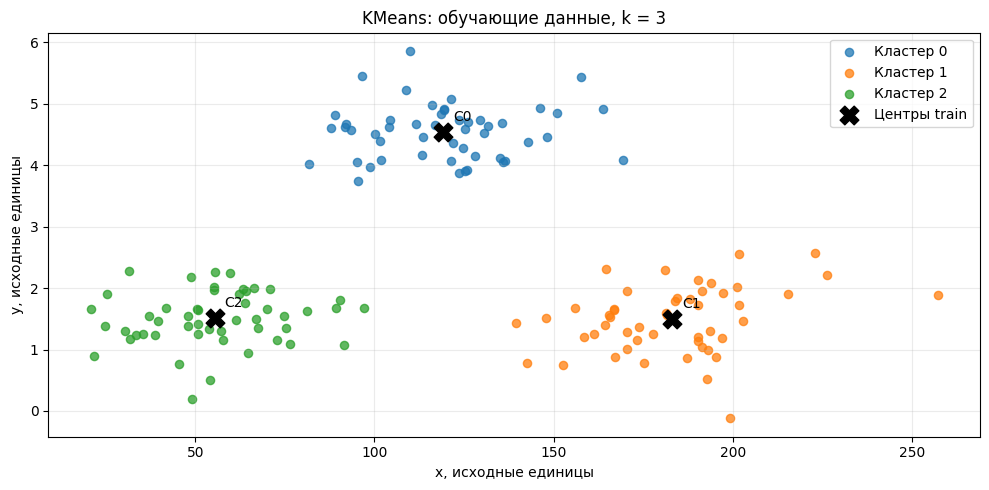

In [108]:
def plot_clusters(data, labels, centers, title):
    fig, ax = plt.subplots(figsize=(10, 5))
    colors = plt.get_cmap('tab10')
    for label in range(len(centers)):
        points = data.iloc[np.flatnonzero(labels == label)]
        ax.scatter(points['x'], points['y'], s=35, alpha=0.75,
                   color=colors(label), label=f'Кластер {label}')
    ax.scatter(centers[:, 0], centers[:, 1], marker='X', color='black',
               s=180, label='Центры train', zorder=5)
    for label, (x, y) in enumerate(centers):
        ax.annotate(f'C{label}', (x, y), xytext=(7, 8), textcoords='offset points')
    ax.set_xlabel('x, исходные единицы')
    ax.set_ylabel('y, исходные единицы')
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


plot_clusters(df, clusters_3, centers_3,
              'KMeans: обучающие данные, k = 3')

Модель отделяет левое нижнее, верхнее и правое нижнее облака. Центры располагаются внутри соответствующих групп. Визуальное разбиение согласуется с тремя группами, заложенными в генераторе.

## 6. Применение модели к тестовым данным

Генерируем отдельный набор `test = make_data(n=50, seed=43)`. Он содержит новые точки из того же генератора и не используется для обучения модели или стандартизатора.

Преобразуем test уже обученным scaler через `transform`, затем назначаем метки через `predict`. Повторный `fit` на test не выполняем.

Размер test: 150 строк, 2 столбца
Центры после predict не изменились: True

Количество тестовых объектов в кластерах:


,Объектов
Кластер,
0,50
1,50
2,50


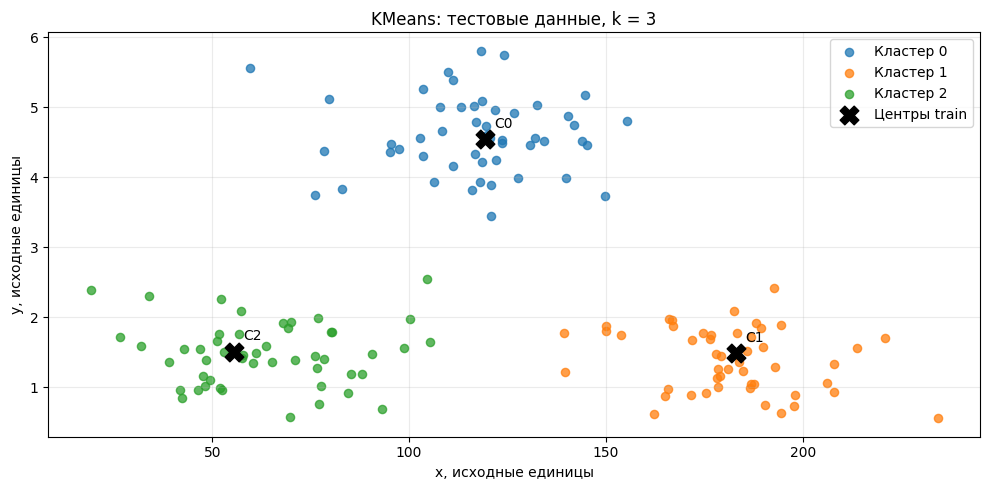

In [109]:
test = make_data(n=50, seed=43)
test_scaled = scaler.transform(test[['x', 'y']])

centers_before = kmeans_3.cluster_centers_.copy()
test_clusters_3 = kmeans_3.predict(test_scaled)

print(f'Размер test: {test.shape[0]} строк, {test.shape[1]} столбца')
print('Центры после predict не изменились:',
      np.array_equal(centers_before, kmeans_3.cluster_centers_))
print('\nКоличество тестовых объектов в кластерах:')
display(pd.Series(test_clusters_3).value_counts().sort_index().rename_axis('Кластер').to_frame('Объектов'))

plot_clusters(test, test_clusters_3, centers_3,
              'KMeans: тестовые данные, k = 3')

150 тестовых объектов распределены по трём группам, по 50 объектов в каждой. На графике показаны центры, полученные на обучающих данных. `predict` не изменяет эти центры, а относит новые точки к ближайшему из них. Если преподаватель предоставит собственный test, потребуется заменить набор и пересчитать результаты.

## 7. Коэффициент силуэта

Вычисляем `silhouette_score` для обучающих и тестовых точек в стандартизированном пространстве. Чем ближе средний силуэт к 1, тем лучше отделены группы; значения около нуля указывают на их перекрытие. Истинная разметка для этой метрики не требуется.

In [110]:
silhouette_train_3 = silhouette_score(X_scaled, clusters_3)
silhouette_test_3 = silhouette_score(test_scaled, test_clusters_3)

print(f'Силуэт train, k = 3: {silhouette_train_3:.6f}')
print(f'Силуэт test, k = 3: {silhouette_test_3:.6f}')

Силуэт train, k = 3: 0.724205
Силуэт test, k = 3: 0.717423


Силуэт равен 0.724205 на обучающих данных и 0.717423 на test. Кластеры хорошо разделены по этой метрике. Силуэт test описывает геометрию новых точек с метками от фиксированной модели; он не является долей правильных ответов.

## 8. Сравнение двух, трёх и четырёх кластеров

Повторяем обучение, получение тестовых меток, визуализацию и расчёт силуэта для `n_clusters = 2` и `n_clusters = 4`. Во всех экспериментах используются одни и те же df, test и scaler.

### 8.1 Два кластера

In [111]:
kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=30, algorithm='lloyd')
clusters_2 = kmeans_2.fit_predict(X_scaled)
test_clusters_2 = kmeans_2.predict(test_scaled)
centers_2 = scaler.inverse_transform(kmeans_2.cluster_centers_)

silhouette_train_2 = silhouette_score(X_scaled, clusters_2)
silhouette_test_2 = silhouette_score(test_scaled, test_clusters_2)
print(f'Силуэт train, k = 2: {silhouette_train_2:.6f}')
print(f'Силуэт test, k = 2: {silhouette_test_2:.6f}')
display(pd.DataFrame({
    'Train': pd.Series(clusters_2).value_counts(),
    'Test': pd.Series(test_clusters_2).value_counts()
}).sort_index().rename_axis('Кластер'))

Силуэт train, k = 2: 0.498910
Силуэт test, k = 2: 0.524303


,Train,Test
Кластер,,
0,100,100
1,50,50


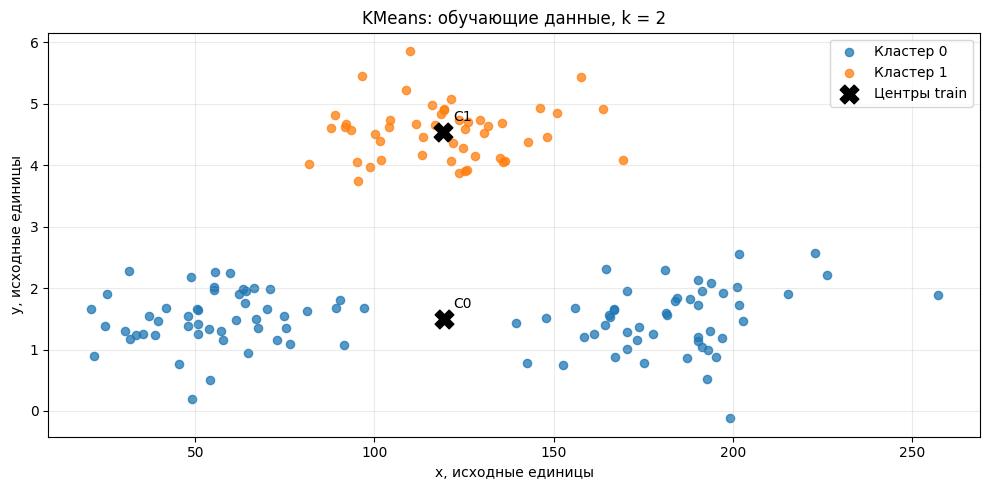

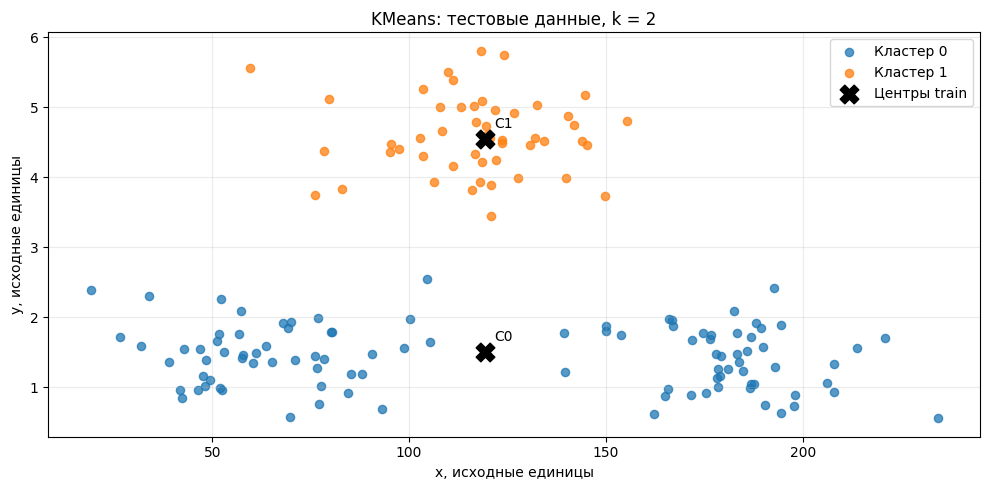

In [112]:
plot_clusters(df, clusters_2, centers_2,
              'KMeans: обучающие данные, k = 2')
plot_clusters(test, test_clusters_2, centers_2,
              'KMeans: тестовые данные, k = 2')

Нижние облака объединены в одну группу из 100 объектов, верхнее облако образует отдельную группу из 50 объектов. Силуэт train 0.498910, test 0.524303, что ниже результатов для трёх групп.

### 8.2 Четыре кластера

In [113]:
kmeans_4 = KMeans(n_clusters=4, random_state=42, n_init=30, algorithm='lloyd')
clusters_4 = kmeans_4.fit_predict(X_scaled)
test_clusters_4 = kmeans_4.predict(test_scaled)
centers_4 = scaler.inverse_transform(kmeans_4.cluster_centers_)

silhouette_train_4 = silhouette_score(X_scaled, clusters_4)
silhouette_test_4 = silhouette_score(test_scaled, test_clusters_4)
print(f'Силуэт train, k = 4: {silhouette_train_4:.6f}')
print(f'Силуэт test, k = 4: {silhouette_test_4:.6f}')
display(pd.DataFrame({
    'Train': pd.Series(clusters_4).value_counts(),
    'Test': pd.Series(test_clusters_4).value_counts()
}).sort_index().rename_axis('Кластер'))

Силуэт train, k = 4: 0.610480
Силуэт test, k = 4: 0.537848


,Train,Test
Кластер,,
0,19,11
1,50,50
2,50,50
3,31,39


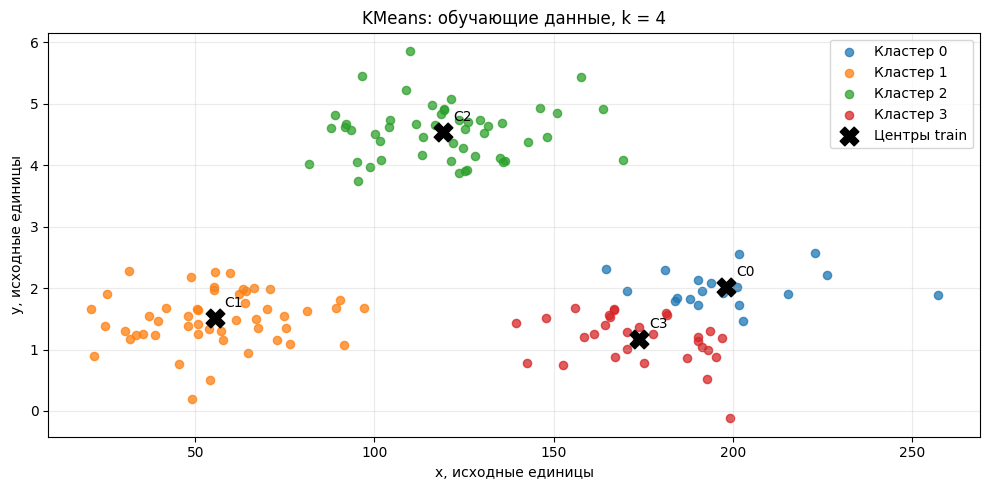

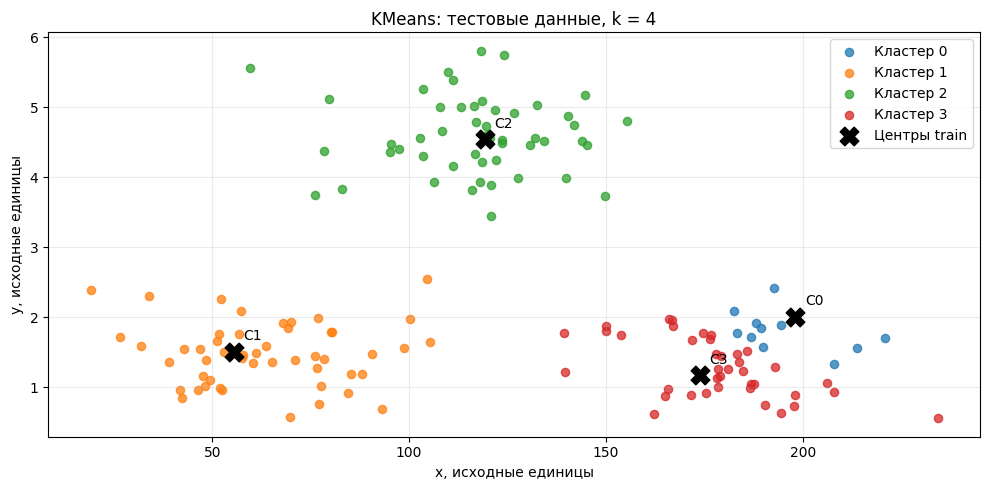

In [114]:
plot_clusters(df, clusters_4, centers_4,
              'KMeans: обучающие данные, k = 4')
plot_clusters(test, test_clusters_4, centers_4,
              'KMeans: тестовые данные, k = 4')

Правое нижнее облако дополнительно разделено на части по 31 и 19 обучающих объектов. На test эти части содержат 39 и 11 объектов. Силуэт train 0.610480, test 0.537848. Дополнительное дробление ухудшает отделённость групп относительно трёх кластеров, хотя уменьшает инерцию.

### 8.3 Таблица результатов

Сопоставляем силуэт на train и test, а также обучающую инерцию. Число кластеров выбираем по обучающему силуэту и графику локтя; тестовые значения используем только как дополнительное описание результата.

,Количество кластеров,Силуэт train,Силуэт test,Инерция train
0,2,0.498910,0.524303,164.673879
1,3,0.724205,0.717423,34.144525
2,4,0.610480,0.537848,28.275933


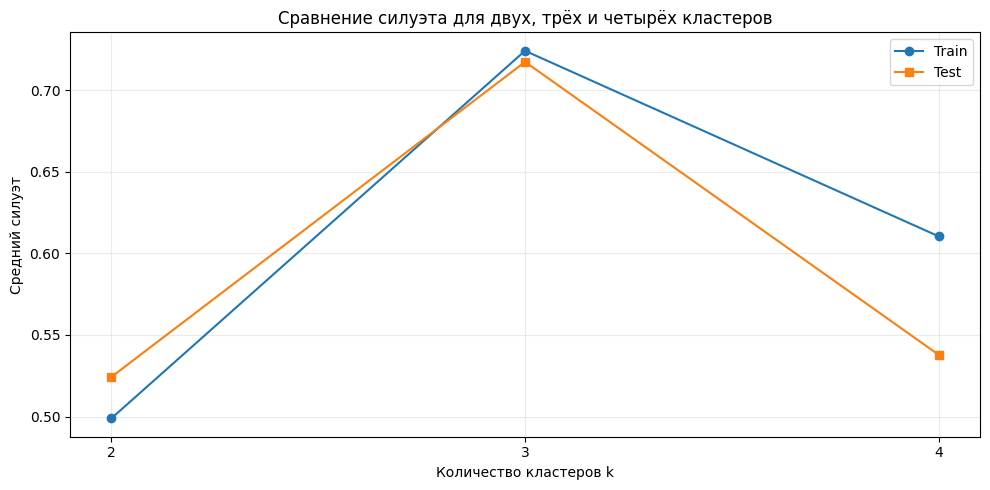

In [115]:
comparison = pd.DataFrame({
    'Количество кластеров': [2, 3, 4],
    'Силуэт train': [silhouette_train_2, silhouette_train_3, silhouette_train_4],
    'Силуэт test': [silhouette_test_2, silhouette_test_3, silhouette_test_4],
    'Инерция train': [kmeans_2.inertia_, kmeans_3.inertia_, kmeans_4.inertia_]
})
display(comparison.round(6))

plt.plot(comparison['Количество кластеров'], comparison['Силуэт train'],
         marker='o', label='Train')
plt.plot(comparison['Количество кластеров'], comparison['Силуэт test'],
         marker='s', label='Test')
plt.xticks([2, 3, 4])
plt.xlabel('Количество кластеров k')
plt.ylabel('Средний силуэт')
plt.title('Сравнение силуэта для двух, трёх и четырёх кластеров')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Среди рассмотренных вариантов наибольший обучающий силуэт при k = 3. На новых точках также получено большее значение для трёх групп. Уменьшение инерции при k = 4 не означает более содержательное разбиение: увеличение числа центров позволяет уменьшить расстояния за счёт дробления облаков.

## 9. Нужно ли делить данные на train и test

Обязательного деления для описательной кластеризации нет. Если цель состоит в изучении групп внутри уже имеющейся таблицы, можно кластеризовать весь набор: целевая переменная для обучения не нужна.

Если затем требуется относить новые объекты к найденным группам, отдельный набор полезен для проверки такого сценария. KMeans поддерживает `predict`, поэтому в этой работе test демонстрирует назначение новых точек к неизменным центрам. Не каждый алгоритм кластеризации поддерживает аналогичное назначение.

В данном решении исходный набор не делился на части: test создан отдельным вызовом той же функции с другим seed. Стандартизатор и модели обучались только на df. Подбор числа кластеров по тестовым метрикам не выполнялся. Проверка одного test не заменяет исследование устойчивости по многим генерациям и не доказывает качество на реальных данных.

## 10. Метод локтя

Перебираем k от 1 до 10 и рассчитываем `inertia_` на стандартизированных обучающих данных. Это сумма квадратов расстояний объектов до назначенных центров. Ищем участок, после которого добавление центра даёт значительно меньшее снижение инерции.

,k,Инерция
0,1,300.000000
1,2,164.673879
2,3,34.144525
3,4,28.275933
4,5,23.990885
5,6,19.961568
6,7,17.631850
7,8,15.728210
8,9,14.053669
9,10,12.328490


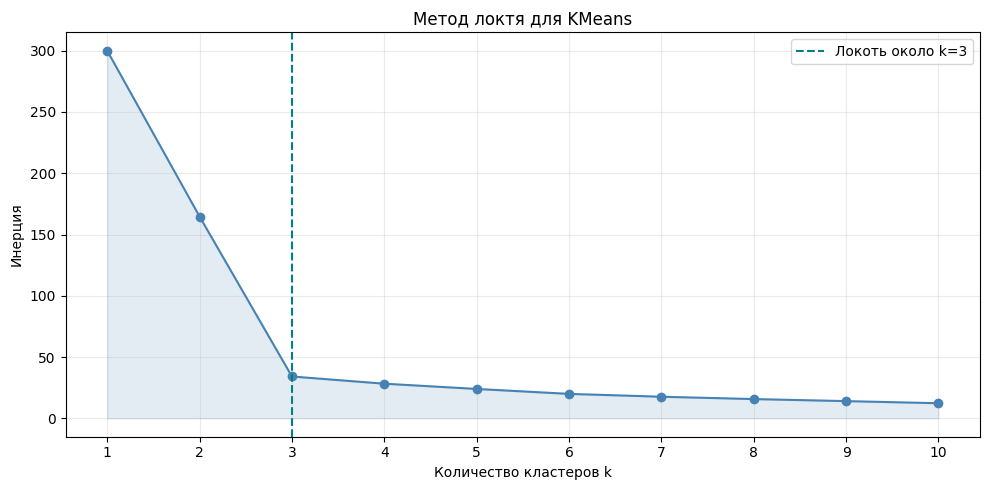

In [116]:
k_values = range(1, 11)
inertia = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=30, algorithm='lloyd')
    model.fit(X_scaled)
    inertia.append(model.inertia_)

elbow = pd.DataFrame({'k': list(k_values), 'Инерция': inertia})
display(elbow.round(6))

plt.plot(elbow['k'], elbow['Инерция'], marker='o', color='steelblue')
plt.fill_between(elbow['k'], elbow['Инерция'], alpha=0.15, color='steelblue')
plt.axvline(x=3, color='teal', linestyle='--', label='Локоть около k=3')
plt.xticks(list(k_values))
plt.xlabel('Количество кластеров k')
plt.ylabel('Инерция')
plt.title('Метод локтя для KMeans')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Инерция уменьшается с 164.673879 при k = 2 до 34.144525 при k = 3. При k = 4 она составляет 28.275933. Снижение от двух к трём примерно 79.27%, от трёх к четырём примерно 17.19%. После k = 3 темп снижения заметно замедляется.

Локоть около k = 3 поддерживает выбор трёх кластеров. Он согласуется с результатом силуэта и заданным механизмом генерации. Метод локтя является эвристикой и не гарантирует единственного правильного числа групп для любых данных.

## Вывод

Сгенерированы 150 обучающих и 150 тестовых искусственных точек с двумя числовыми признаками. Выбраны `n = 50`, `seed = 42` для обучающего набора и `seed = 43` для `test`. Пропусков и дубликатов в данных нет. Выполнена стандартизация, после которой обучающие признаки имеют среднее около нуля и стандартное отклонение 1.

`StandardScaler` обучен только на обучающем наборе `df`, а `test` обработан через `transform`, поэтому тестовые данные не повлияли на параметры масштабирования. KMeans для 2, 3 и 4 кластеров обучен методом `fit_predict`. Метки для `test` назначены методом `predict` без изменения центров.

Наибольший коэффициент силуэта получен для трёх кластеров: 0.724205 на обучающих данных и 0.717423 на тестовых. Метод локтя подтверждает этот выбор: после `k = 3` снижение инерции заметно замедляется. Для выполненного эксперимента обоснованы три кластера.

При двух кластерах разные облака объединяются, при четырёх одно облако дополнительно дробится. Три кластера дают наиболее отделённые группы среди рассмотренных вариантов и согласуются с конструкцией генератора. Вывод относится к выбранным данным и параметрам, а не ко всем задачам кластеризации.

Разделение на `train` и `test` не обязательно для описательного анализа всей таблицы. Отдельные данные полезны, когда проверяется применение найденных центров к новым точкам. В этом исследовании использован отдельный `test`, созданный той же функцией.